# Gaussian: paper figures and local-peak errors

These cells use the supplied 50-repeat results. They do not launch new experiments. Error curves show mean log10 errors and one standard deviation in log space.

In [1]:
%matplotlib inline
from pathlib import Path
from types import SimpleNamespace
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import FuncNorm
from matplotlib.ticker import FuncFormatter, FormatStrFormatter
from IPython.display import display
HERE=Path.cwd()
DATA=HERE/'Data'
FIG=HERE/'Figures'
FIG.mkdir(exist_ok=True)
from PCA_Theta import load_result
METHODS=['random_ols','lhs_ols','theta_ols','pca_theta_ols','qv_theta_ols','qv_pca_theta_ols']
LABELS=['Random-OLS','LHS-OLS',r'$\Theta$-OLS',r'PCA-$\Theta$-OLS',r'$\eta$-$\Theta$-OLS',r'$\eta$-PCA-$\Theta$-OLS']
COLORS=['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#17becf']
CONTRAST_POWER=2.0

def shared_norm(densities):
    maximum = float(np.max(densities))
    step = 1. if maximum <= 5. else (5. if maximum <= 30. else 10.)
    upper = max(2., float(np.ceil(maximum / step) * step))
    # c=(rho**2-1)/(rho**2+1): zero density -> -1, uniform -> 0.
    # Scale the positive branch to the common upper limit so uniform is
    # exactly the white midpoint, including figures with a different range.
    upper_contrast = (upper**CONTRAST_POWER - 1.) / (upper**CONTRAST_POWER + 1.)
    def forward(value):
        power = np.power(value, CONTRAST_POWER)
        contrast = (power - 1.) / (power + 1.)
        return np.where(contrast >= 0., contrast / upper_contrast, contrast)
    def inverse(value):
        contrast = np.where(value >= 0., value * upper_contrast, value)
        return np.power((1. + contrast) / (1. - contrast), 1. / CONTRAST_POWER)
    return FuncNorm((forward, inverse), vmin=0., vmax=upper, clip=False)

## Error curves and common degree

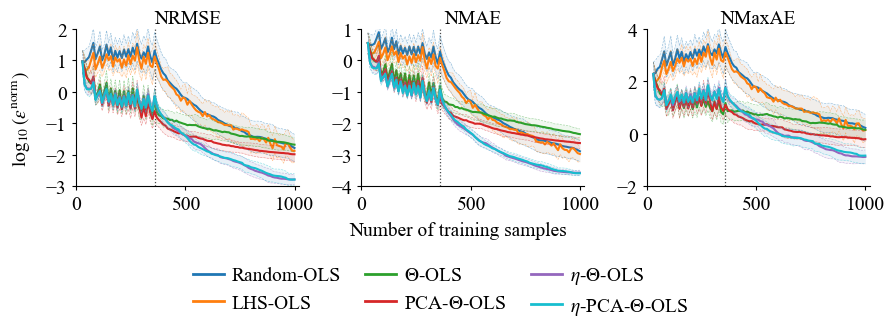

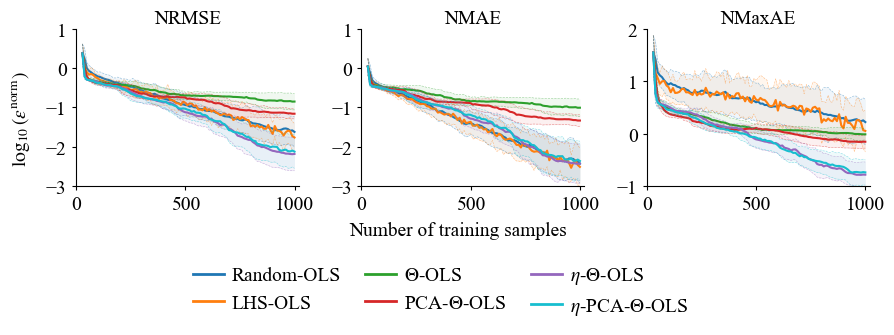

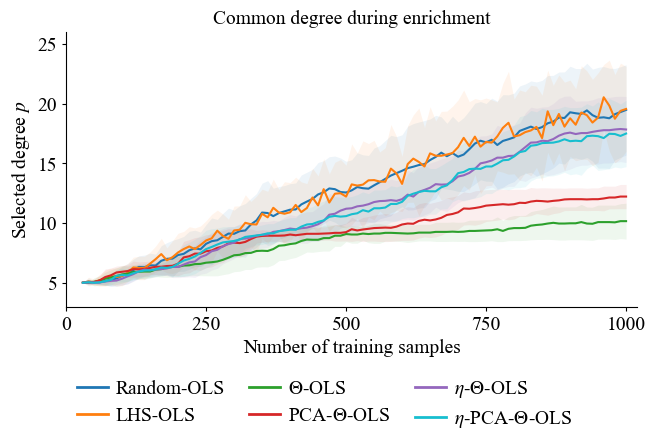

In [2]:
data=np.load(DATA/'results.npz',allow_pickle=False)
WIDTH = 9.0
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],
    'mathtext.fontset':'stix','font.size':14,'axes.labelsize':14,'axes.titlesize':14,
    'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14,'legend.frameon':False,
    'axes.grid':False,'pdf.fonttype':42,'ps.fonttype':42,'axes.linewidth':.8,'lines.linewidth':1.5})
fmt = FuncFormatter(lambda x,_: f'{x:g}')
metrics = ('nrmse','nmae','nmaxae')
titles = ('NRMSE','NMAE','NMaxAE')
# (lower bound, upper bound, tick step). Limits include every mean curve.
ERROR_LIMITS = {
    ('shared', 'nrmse'): (-3, 2, 1),
    ('shared', 'nmae'): (-4, 1, 1),
    ('shared', 'nmaxae'): (-2, 4, 2),
    ('loo', 'nrmse'): (-3, 1, 1),
    ('loo', 'nmae'): (-3, 1, 1),
    ('loo', 'nmaxae'): (-1, 2, 1),
    ('loo', 'nrmse_outputs'): (-3, 1, 1),
    ('loo', 'nmae_outputs'): (-4, 1, 1),
    ('loo', 'nmaxae_outputs'): (-2, 2, 1),
}
def save(fig,name):
    fig.savefig(FIG/(name+'.pdf'),dpi=240,facecolor='white')
    display(fig); plt.close(fig)

def clean(ax):
    ax.spines[['top','right']].set_visible(False)
    ax.tick_params(direction='out',length=3)
    ax.xaxis.set_major_formatter(fmt)

def legend(fig,y=.008):
    handles=[Line2D([],[],color=c,lw=2,label=l) for c,l in zip(COLORS,LABELS)]
    fig.legend(handles=handles,loc='lower center',ncol=3,bbox_to_anchor=(.5,y),
               handlelength=1.6,columnspacing=1.25,handletextpad=.4,borderaxespad=0)

def curve(ax,suite,key,output=None):
    n=data['n']
    low,high,step = ERROR_LIMITS[suite,key]
    ticks = np.arange(low, high+1, step)
    assert len(ticks) >= 4 and ticks[-1] == high
    for m,c in enumerate(COLORS):
        v=data[f'{suite}_{m}_{key}']
        if output is not None: v=v[:,:,output]
        v=np.log10(v); mean=v.mean(axis=0);sd=v.std(axis=0,ddof=1)
        assert np.all((low < mean) & (mean < high)), (suite, key, output, m)
        ax.fill_between(n,mean-sd,mean+sd,color=c,alpha=.065,linewidth=0)
        for bound in (mean-sd,mean+sd):
            ax.plot(n,bound,color=c,ls='--',lw=.44,alpha=.48)
        ax.plot(n,mean,color=c,lw=1.5)
    ax.set(xlim=(0,1020),xticks=(0,500,1000))
    ax.set(yticks=ticks, ylim=(low, high))
    clean(ax)

def errors(suite,name):
    fig,axes=plt.subplots(1,3,figsize=(WIDTH,3.38))
    for ax,k,t in zip(axes,metrics,titles):
        curve(ax,suite,k)
        if suite=='shared': ax.axvline(360,color='.28',ls=':',lw=.9,zorder=0)
        ax.set_title(t,pad=4)
    fig.text(.034,.62,r'$\log_{10}(\varepsilon^{\mathrm{norm}})$',rotation=90,ha='center',va='center')
    fig.text(.52,.275,'Number of training samples',ha='center')
    fig.subplots_adjust(left=.095,right=.977,bottom=.418,top=.885,wspace=.28)
    legend(fig);save(fig,name)

def common_degree():
    fig, ax = plt.subplots(figsize=(6.8, 4.5))
    n = data['n']
    for method, color in enumerate(COLORS):
        degrees = data[f'loo_{method}_p_selected']
        assert degrees.shape == (50, len(n))
        mean = degrees.mean(axis=0)
        sd = degrees.std(axis=0, ddof=1)
        ax.fill_between(n, mean-sd, mean+sd, color=color, alpha=.08, linewidth=0)
        ax.plot(n, mean, color=color)
    clean(ax)
    ax.set(xlim=(0, 1020), xticks=[0, 250, 500, 750, 1000], ylim=(3, 26),
           yticks=[5, 10, 15, 20, 25], xlabel='Number of training samples',
           ylabel=r'Selected degree $p$', title='Common degree during enrichment')
    fig.subplots_adjust(left=.12, right=.96, bottom=.30, top=.91)
    legend(fig)
    save(fig, 'gaussian_common_P_selection')


errors('shared','gaussian_maxp_error')
errors('loo','gaussian_commonp_error')
common_degree()

## Worst-prediction field comparison

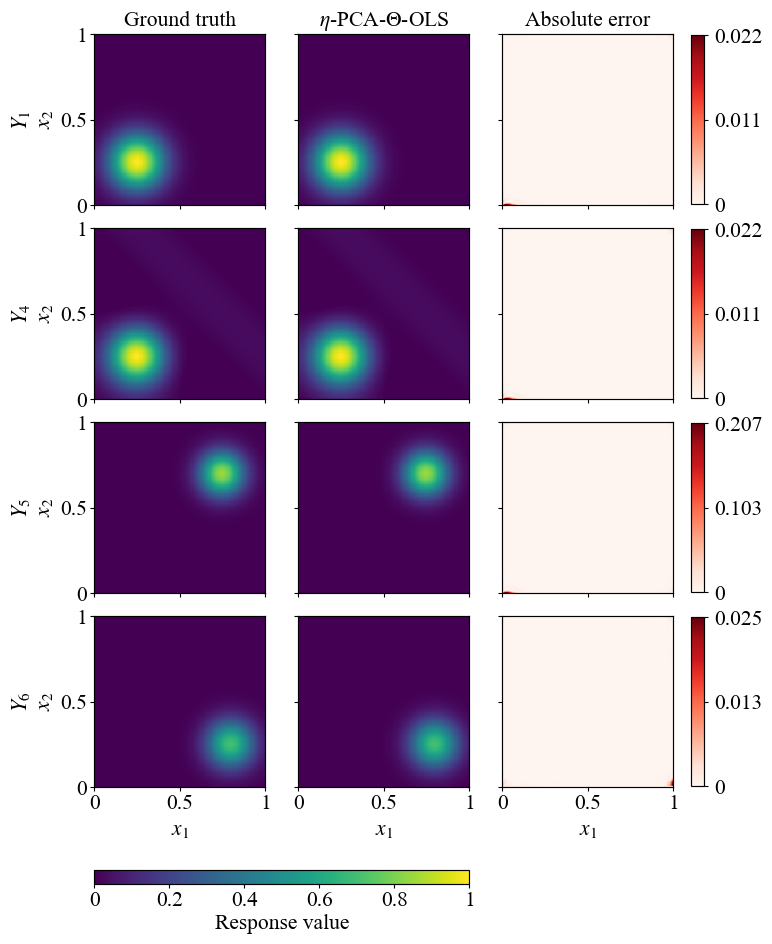

In [3]:
from matplotlib.colors import Normalize
OUTPUTS=(0,3,4,5)
FIGURES=FIG
NAME='gaussian_eta_field'
def draw_fields(truth, prediction, error):
    plt.rcParams.update({
        "font.family":"serif", "font.serif":["Times New Roman","DejaVu Serif"],
        "mathtext.fontset":"stix", "font.size":15.5, "axes.titlesize":15.5,
        "axes.labelsize":15.5, "xtick.labelsize":15.5, "ytick.labelsize":15.5,
        "pdf.fonttype":42, "ps.fonttype":42, "axes.grid":False, "axes.linewidth":.85,
    })
    width, height, side = 8.2, 9.45, 1.71
    fig = plt.figure(figsize=(width,height), facecolor="white")
    def axes(x,y,w,h):
        return fig.add_axes((x/width,y/height,w/width,h/height))
    fmt = FuncFormatter(lambda value, pos: f"{value:g}")
    field_norm = Normalize(0,1)
    for row,j in enumerate(OUTPUTS):
        y = 7.34-row*1.94
        for col,(x,values) in enumerate(zip((.94,2.98,5.02),(truth,prediction,error))):
            ax = axes(x,y,side,side)
            array=values[:,:,j]
            if col < 2:
                field = ax.imshow(array,origin="lower",extent=(0,1,0,1),cmap="viridis",
                                  interpolation="nearest",norm=field_norm)
            else:
                maximum = float(array.max())
                im = ax.imshow(array,origin="lower",extent=(0,1,0,1),cmap="Reds",
                               interpolation="nearest",vmin=0,vmax=maximum)
                cb=fig.colorbar(im,cax=axes(6.91,y+.01,.13,side-.02),ticks=[0,maximum/2,maximum])
                cb.ax.set_yticklabels(["0",f"{maximum/2:.3f}",f"{maximum:.3f}"])
                cb.ax.tick_params(length=3,pad=4)
            ax.set(xticks=[0,.5,1],yticks=[0,.5,1],xlabel=r"$x_1$" if row == 3 else "")
            ax.tick_params(direction="out",length=3,pad=2,labelbottom=row==3,labelleft=col==0)
            ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
            if col == 0:
                ax.set_ylabel(rf"$Y_{{{j+1}}}$"+"\n"+r"$x_2$",labelpad=4)
            if row == 0:
                ax.set_title(["Ground truth", r"$\eta$-PCA-$\Theta$-OLS", "Absolute error"][col],pad=6)
    bar=fig.colorbar(field,cax=axes(.94,.55,3.75,.14),orientation="horizontal",ticks=[0,.2,.4,.6,.8,1])
    bar.ax.xaxis.set_major_formatter(fmt)
    bar.ax.tick_params(length=3,pad=2)
    bar.set_label("Response value",labelpad=2)
    fig.savefig(FIGURES/(NAME+".pdf"),dpi=260,facecolor="white")
    display(fig); plt.close(fig)
with np.load(DATA/'fields.npz',allow_pickle=False) as values:
    draw_fields(*[values[k] for k in ('truth','prediction','error')])

## Sampling density

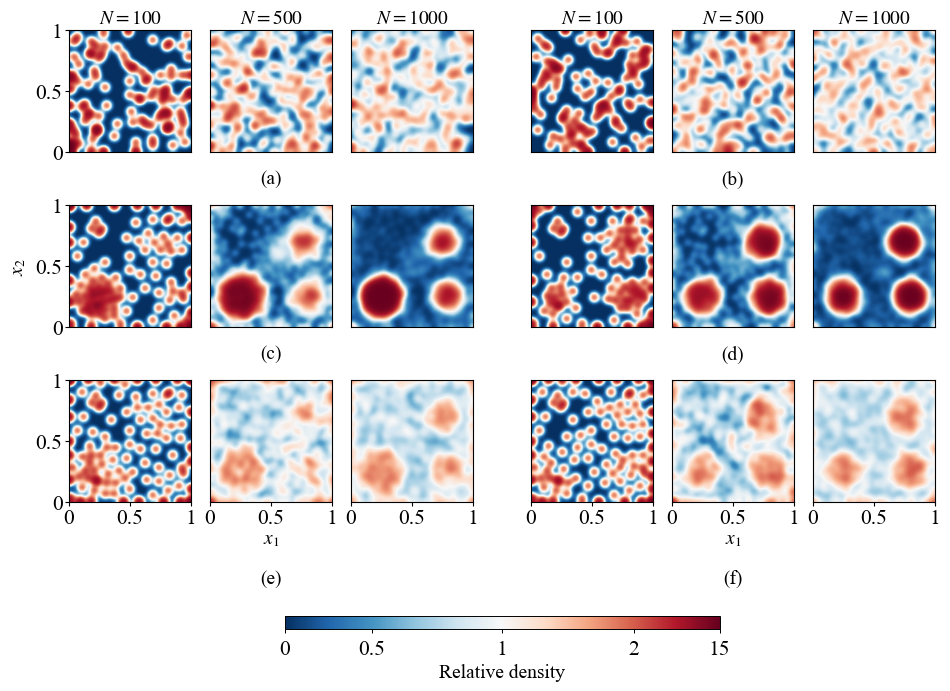

In [4]:
def main():
    with np.load(DATA / "results.npz") as data:
        densities = np.stack([data[f"density_{m}"] for m in range(6)])
    np.testing.assert_allclose(densities.mean(axis=(-2, -1)), 1.0)
    norm = shared_norm(densities)
    plt.rcParams.update({
        "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
        "mathtext.fontset": "stix", "font.size": 14, "axes.labelsize": 14,
        "axes.titlesize": 14, "axes.linewidth": .8, "axes.grid": False,
        "pdf.fonttype": 42, "ps.fonttype": 42,
    })
    side, row_gap, col_gap, group_gap = 1.22, .53, .19, .58
    left, bottom = .62, 1.82
    group_width = 3 * side + 2 * col_gap
    grid_width = 2 * group_width + group_gap
    grid_height = 3 * side + 2 * row_gap
    width, height = left + grid_width + .16, bottom + grid_height + .40
    fig = plt.figure(figsize=(width, height))

    def axes(x, y, w, h):
        return fig.add_axes([x/width, y/height, w/width, h/height])

    for method, letter in enumerate("abcdef"):
        row, group = divmod(method, 2)
        group_left = left + group * (group_width + group_gap)
        y = bottom + (2 - row) * (side + row_gap)
        for col, n in enumerate((100, 500, 1000)):
            ax = axes(group_left + col * (side + col_gap), y, side, side)
            image = ax.imshow(densities[method, col].T, origin="lower", extent=(0, 1, 0, 1),
                              interpolation="bilinear", norm=norm, cmap="RdBu_r", rasterized=True)
            ax.set(xticks=[0, .5, 1], yticks=[0, .5, 1])
            ax.xaxis.set_major_formatter(FormatStrFormatter("%g"))
            ax.yaxis.set_major_formatter(FormatStrFormatter("%g"))
            show_y_ticks = group == 0 and col == 0
            ax.tick_params(bottom=row == 2, labelbottom=row == 2, left=show_y_ticks,
                           labelleft=show_y_ticks, length=2.6, pad=2)
            if row == 0:
                ax.set_title(rf"$N={n}$", pad=5)
            if row == 2 and col == 1:
                ax.set_xlabel(r"$x_1$", labelpad=1)
        label_y = y - (.76 if row == 2 else row_gap / 2)
        fig.text((group_left + group_width / 2)/width, label_y/height, f"({letter})",
                 ha="center", va="center")

    mid_y = bottom + grid_height/2
    fig.text(.12/width, mid_y/height, r"$x_2$", rotation=90, ha="center", va="center")
    bar_width = 4.35
    bar_axis = axes(left + (grid_width - bar_width)/2, .55, bar_width, .13)
    bar = fig.colorbar(image, cax=bar_axis, orientation="horizontal", ticks=[0, .5, 1, 2, norm.vmax],
                       format=FormatStrFormatter("%g"))
    bar.minorticks_off()
    bar.ax.tick_params(length=3, width=.7, pad=4)
    bar.outline.set_linewidth(.7)
    bar.set_label("Relative density", labelpad=3)
    fig.savefig(FIG / "gaussian_sampling_density.pdf",
                dpi=240, facecolor="white")
    display(fig); plt.close(fig)
main()

## PCA contributions and computational time

pca_theta_ols mean (%) [7.02820e+01 2.23519e+01 7.29960e+00 4.48000e-02 1.87000e-02 3.00000e-03] retained counts (array([3]), array([50], dtype=int64))
qv_pca_theta_ols mean (%) [6.77415e+01 1.91999e+01 1.28278e+01 1.43700e-01 7.49000e-02 1.22000e-02] retained counts (array([3]), array([50], dtype=int64))


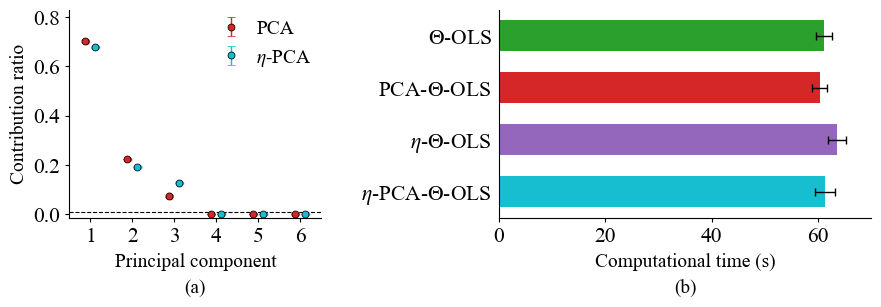

In [5]:
def draw_pca(pca, ratios_by_method):
    component = np.arange(1, 7)
    rng = np.random.default_rng(410)
    for method, offset, label in [(3, -.12, 'PCA'), (5, .12, r'$\eta$-PCA')]:
        ratios = ratios_by_method[method]
        assert ratios.shape == (50, 6)
        for j, k in enumerate(component):
            jitter = rng.uniform(-.052, .052, size=len(ratios))
            pca.scatter(k + offset + jitter, ratios[:, j], s=8, color=COLORS[method],
                        alpha=.27, linewidths=0)
        pca.errorbar(component + offset, ratios.mean(axis=0), yerr=ratios.std(axis=0, ddof=1),
                     fmt='o', ms=5, color=COLORS[method], mec='black', mew=.55,
                     lw=1.05, capsize=3, label=label)
    pca.axhline(.01, ls='--', lw=.8, color='black')
    clean(pca)
    pca.set(xticks=component, xlim=(.5, 6.5), ylim=(-.015, .83), yticks=[0, .2, .4, .6, .8],
            xlabel='Principal component', ylabel='Contribution ratio')
    pca.legend(loc='upper right', handlelength=1, borderaxespad=.1)

def main(single_panel=True):
    ratios_by_method = {m: data[f'pcs_{m}'] for m in (3, 5)}
    for m, ratios in ratios_by_method.items():
        print(METHODS[m], 'mean (%)', np.round(100 * ratios.mean(axis=0), 4),
              'retained counts', np.unique((ratios >= .01).sum(axis=1), return_counts=True))
    if single_panel:
        single, ax = plt.subplots(figsize=(4.15, 3.0))
        single.subplots_adjust(left=.19, bottom=.23, top=.95, right=.97)
        draw_pca(ax, ratios_by_method)
        save(single, 'gaussian_PCA_pce_predictions')

    fig = plt.figure(figsize=(WIDTH, 3.2))
    pca = fig.add_axes([.080, .31, .28, .65])
    time = fig.add_axes([.557, .31, .414, .65])
    draw_pca(pca, ratios_by_method)
    adaptive_methods = (2, 3, 4, 5)
    for row, method in enumerate(adaptive_methods):
        raw = data[f'time_{method}']
        assert raw.shape == (50, 6)
        # The sixth column reconciles the recorded construction time, including design generation.
        totals = raw.sum(axis=1)
        time.barh(row, totals.mean(), height=.60, color=COLORS[method], linewidth=0,
                  xerr=totals.std(ddof=1),
                  error_kw={'ecolor':'black', 'elinewidth':1, 'capsize':3, 'capthick':1})
    clean(time)
    time.set(yticks=np.arange(len(adaptive_methods)), yticklabels=[LABELS[m] for m in adaptive_methods],
             ylim=(len(adaptive_methods)-.5,-.5),
             xlim=(0, 70), xticks=[0, 20, 40, 60], xlabel='Computational time (s)')
    time.tick_params(axis='y', length=0, pad=5)
    for axis, label in ((pca, '(a)'), (time, '(b)')):
        bounds = axis.get_position()
        fig.text((bounds.x0 + bounds.x1) / 2, .091, label, ha='center', va='center')
    save(fig, 'gaussian_PCA')
main(single_panel=False)

## Local peak errors at the same final degree

In [6]:
from scipy.special import eval_legendre
import numpy as np

EXAMPLE_NAME = "gaussian"
BOUNDS = [(0.0, 1.0), (0.0, 1.0)]


def gaussian_2d(x1, x2, c1, c2, s1, s2):
    return np.exp(-((x1 - c1) / s1) ** 2 - ((x2 - c2) / s2) ** 2)


def evaluate(X):
    X = np.asarray(X, dtype=float)
    x1, x2 = X[:, 0], X[:, 1]
    g0 = gaussian_2d(x1, x2, 0.25, 0.25, 0.16, 0.16)
    return np.column_stack([
        g0,
        1.03 * g0 + 0.02 * np.sin(2.0 * np.pi * x1),
        0.97 * g0 + 0.03 * np.cos(2.0 * np.pi * x2),
        g0 + 0.03 * np.sin(2.0 * np.pi * (x1 + x2)),
        0.85 * gaussian_2d(x1, x2, 0.75, 0.70, 0.13, 0.13),
        0.70 * gaussian_2d(x1, x2, 0.80, 0.25, 0.14, 0.14),
    ])


def build_model(args):
    return evaluate, {"n_outputs": 6}
def gaussian():
    with np.load(DATA/'peak_models.npz',allow_pickle=False) as z:
        beta,mi=z['coefficients'],z['multi_indices']
    assert beta.shape==(4,50,351,6)
    dx,dy=np.meshgrid(np.arange(-40,41),np.arange(-40,41))
    inside=dx*dx+dy*dy<=1600
    lattice=np.column_stack((dx[inside],dy[inside]))*.1/40
    centres=np.array([[.25,.25],[.75,.70],[.80,.25]])
    model=SimpleNamespace(evaluate=evaluate)
    local=np.zeros((4,50,6))
    for region,centre in enumerate(centres):
        x=centre+lattice
        y=model.evaluate(x)
        z=2*x-1
        v=[np.column_stack([np.sqrt(2*k+1)*eval_legendre(k,z[:,j]) for k in range(26)]) for j in range(2)]
        a=v[0][:,mi[:,0]]*v[1][:,mi[:,1]]
        outputs=range(4) if region==0 else [region+3]
        for m in range(4):
            pred=(a@beta[m].transpose(1,0,2).reshape(351,-1)).reshape(len(x),50,6)
            error=np.abs(pred-y[:,None,:]).mean(axis=0)
            for j in outputs: local[m,:,j]=error[:,j]
    regional=np.stack((local[:,:,:4].mean(axis=2),local[:,:,4],local[:,:,5]),axis=2)
    mean,sd=regional.mean(axis=1),regional.std(axis=1,ddof=1)
    from IPython.display import Markdown
    lines=['| Method | Shared peak | Y5 peak | Y6 peak |','|---|---:|---:|---:|']
    for label,mu,sigma in zip(LABELS[2:],mean,sd):
        lines.append('| '+label+' | '+' | '.join(f'{x*1e6:.2f} ± {s*1e6:.2f}' for x,s in zip(mu,sigma))+' |')
    display(Markdown('Local MAE at final p=25, mean ± sample SD, in units of 1e-6.\n\n'+'\n'.join(lines)))

gaussian()

Local MAE at final p=25, mean ± sample SD, in units of 1e-6.

| Method | Shared peak | Y5 peak | Y6 peak |
|---|---:|---:|---:|
| $\Theta$-OLS | 0.94 ± 0.39 | 29.45 ± 7.48 | 3.74 ± 1.50 |
| PCA-$\Theta$-OLS | 1.84 ± 0.55 | 23.45 ± 4.98 | 4.69 ± 2.00 |
| $\eta$-$\Theta$-OLS | 5.72 ± 0.62 | 93.28 ± 6.08 | 18.99 ± 2.09 |
| $\eta$-PCA-$\Theta$-OLS | 5.95 ± 0.59 | 87.54 ± 6.21 | 18.10 ± 2.04 |